In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

In [2]:
DATA_PATH = Path("../data/raw/creditcard.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset carregado com sucesso!")
print(f"Linhas: {df.shape[0]:,}")
print(f"Colunas: {df.shape[1]}")

df.head()

Dataset carregado com sucesso!
Linhas: 284,807
Colunas: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [5]:
class_counts = df["Class"].value_counts().sort_index()

class_percentages = (
    df["Class"].value_counts(normalize=True).sort_index() * 100
)

print("Quantidade por classe:")
print(class_counts)

print("\nPercentual por classe:")
print(class_percentages.round(4))

Quantidade por classe:
Class
0    284315
1       492
Name: count, dtype: int64

Percentual por classe:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


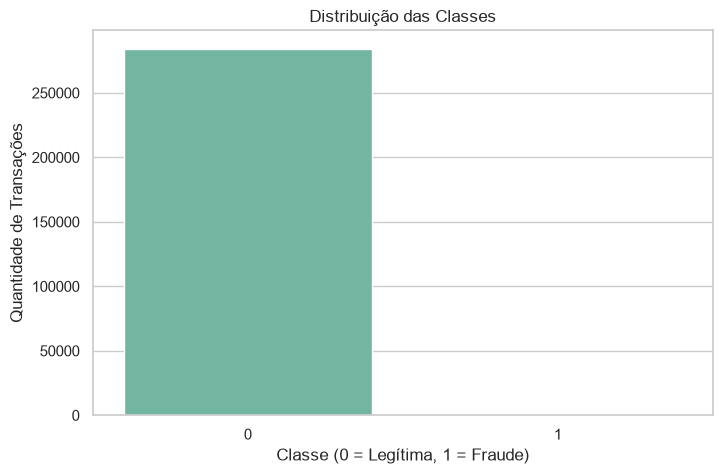

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Class",
    hue="Class",
    palette="Set2",
    legend=False
)

plt.title("Distribuição das Classes")
plt.xlabel("Classe (0 = Legítima, 1 = Fraude)")
plt.ylabel("Quantidade de Transações")

plt.show()

In [7]:
amount_stats = df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(amount_stats.round(2))

        count    mean  median     std  min       max
Class                                               
0      284315   88.29   22.00  250.11  0.0  25691.16
1         492  122.21    9.25  256.68  0.0   2125.87


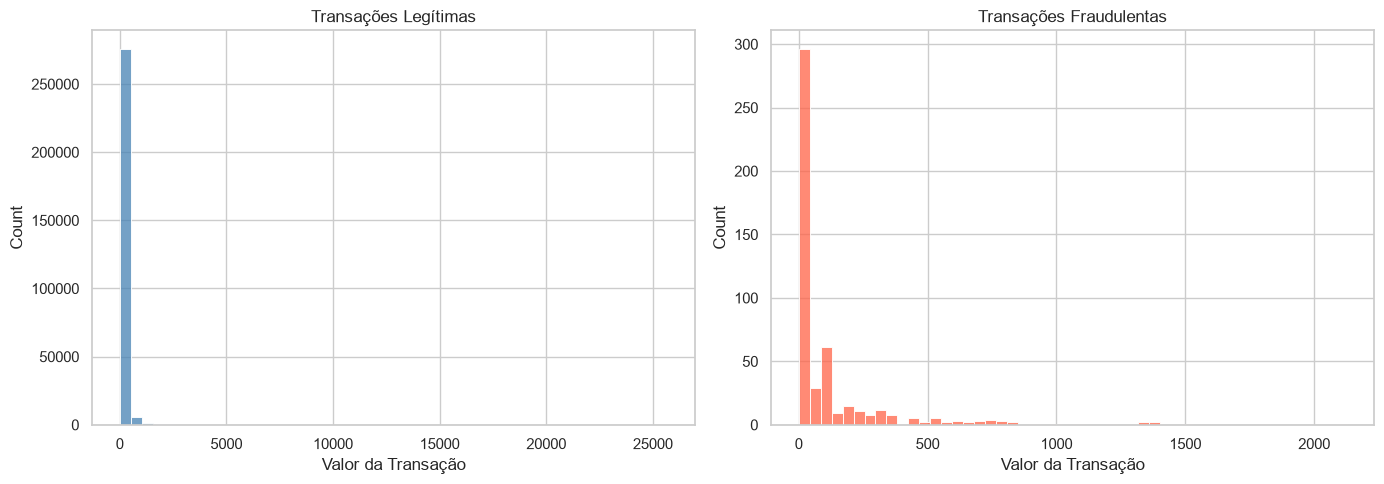

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df[df["Class"] == 0],
    x="Amount",
    bins=50,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Transações Legítimas")
axes[0].set_xlabel("Valor da Transação")

sns.histplot(
    data=df[df["Class"] == 1],
    x="Amount",
    bins=50,
    ax=axes[1],
    color="tomato"
)

axes[1].set_title("Transações Fraudulentas")
axes[1].set_xlabel("Valor da Transação")

plt.tight_layout()
plt.show()

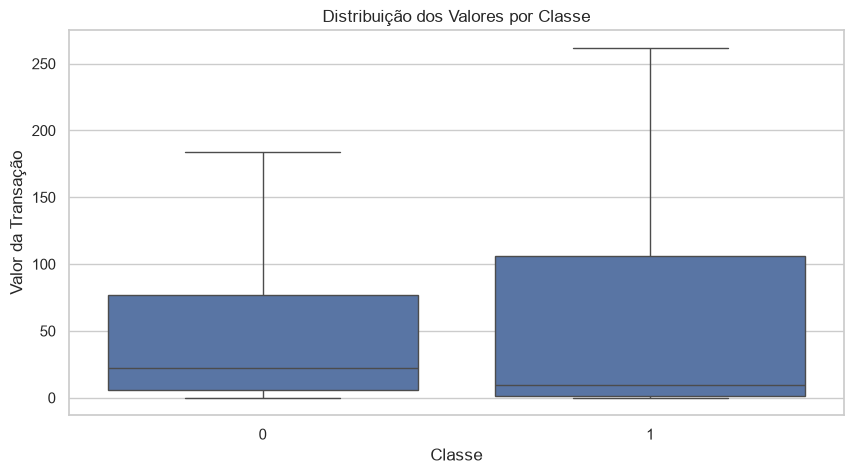

In [9]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount",
    showfliers=False
)

plt.title("Distribuição dos Valores por Classe")
plt.xlabel("Classe")
plt.ylabel("Valor da Transação")

plt.show()

In [10]:
correlations = df.corr(numeric_only=True)["Class"]

correlations = correlations.drop("Class")

correlations = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

print(correlations.head(10))

V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V11    0.154876
V4     0.133447
V18   -0.111485
Name: Class, dtype: float64


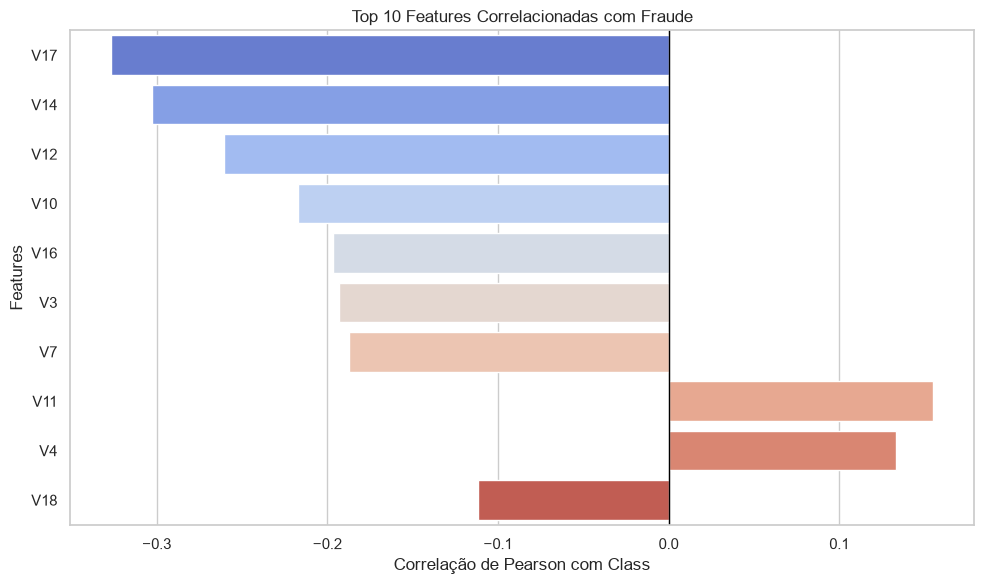

In [11]:
top_correlations = correlations.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_correlations.values,
    y=top_correlations.index,
    hue=top_correlations.index,
    palette="coolwarm",
    legend=False
)

plt.title("Top 10 Features Correlacionadas com Fraude")
plt.xlabel("Correlação de Pearson com Class")
plt.ylabel("Features")

plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

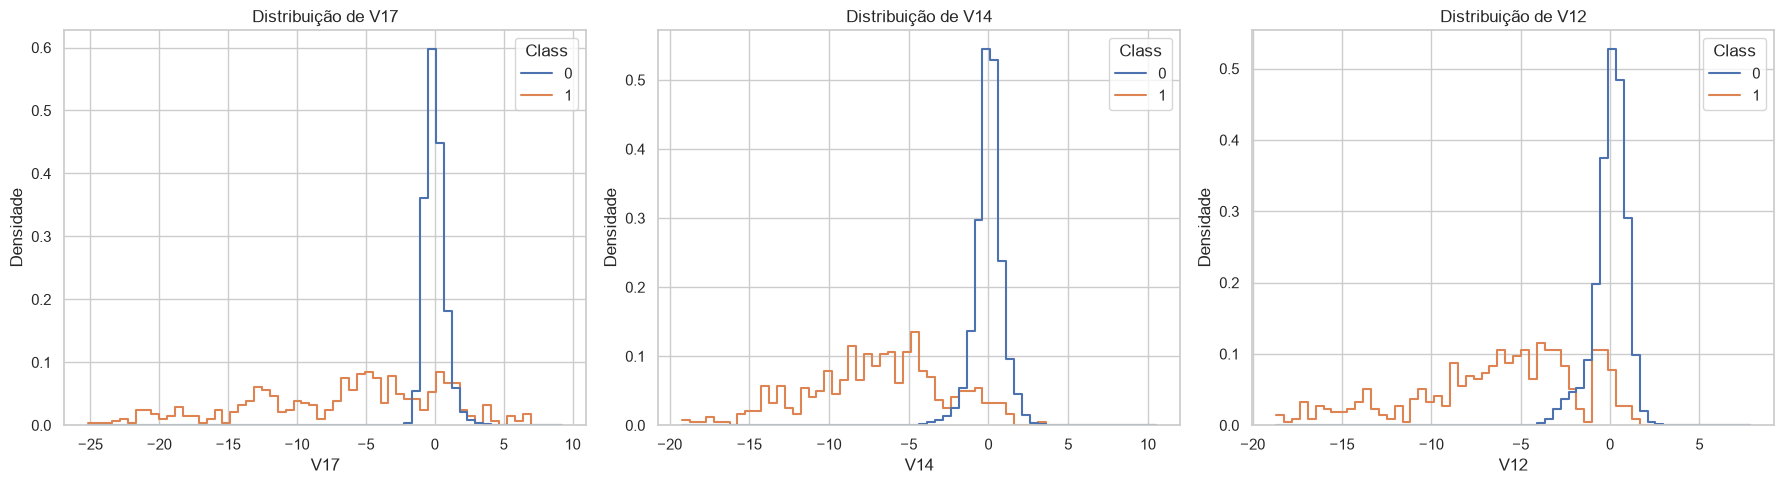

In [12]:
features = ["V17", "V14", "V12"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feature in enumerate(features):
    sns.histplot(
        data=df,
        x=feature,
        hue="Class",
        bins=60,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribuição de {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Densidade")

plt.tight_layout()
plt.show()

In [13]:
feature_stats = df.groupby("Class")[features].agg(
    ["mean", "median", "std"]
)

print(feature_stats.round(3))

         V17                  V14                  V12              
        mean median    std   mean median    std   mean median    std
Class                                                               
0      0.012 -0.065  0.749  0.012  0.052  0.897  0.011  0.142  0.946
1     -6.666 -5.303  6.971 -6.972 -6.730  4.279 -6.259 -5.503  4.654


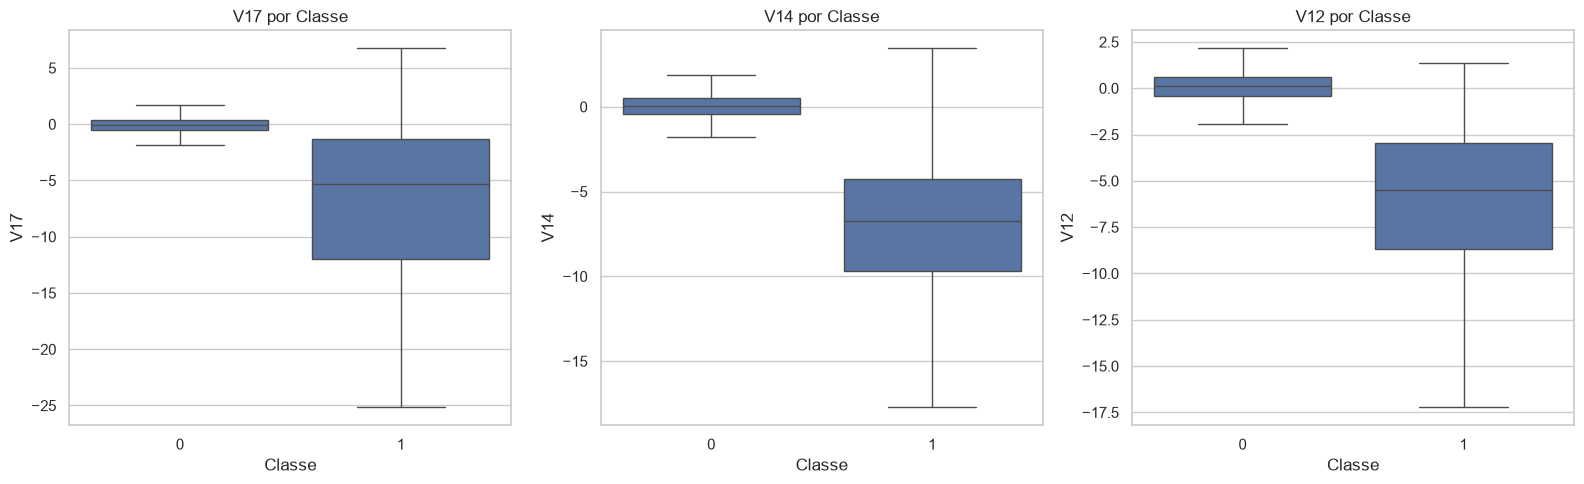

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, feature in enumerate(features):
    sns.boxplot(
        data=df,
        x="Class",
        y=feature,
        showfliers=False,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} por Classe")
    axes[i].set_xlabel("Classe")
    axes[i].set_ylabel(feature)

plt.tight_layout()
plt.show()

In [ ]:
## Conclusões da Análise Exploratória

### Dataset
#- 284.807 transações e 31 colunas.
#- 30 features e uma variável-alvo (`Class`).
#- 284.315 transações legítimas e 492 fraudulentas.
#- Não foram encontrados valores ausentes.

### Desbalanceamento
#- Aproximadamente 0,173% das transações são fraudulentas.
#- Accuracy isoladamente não é adequada para avaliar o modelo.
#- Utilizaremos métricas como precision, recall, F1-score e PR-AUC.

### Valores das transações
#- Média das legítimas: 88,29; média das fraudes: 122,21.
#- Mediana das legítimas: 22,00; mediana das fraudes: 9,25.
#- A diferença entre média e mediana sugere distribuições assimétricas.

### Correlações
#- V17, V14 e V12 apresentaram as maiores correlações lineares absolutas com `Class`.
#- As três features apresentaram médias mais negativas nas transações fraudulentas.
#- Correlação não garante importância preditiva nem causalidade.

### Cuidados para o treinamento
#- Separar treino, validação e teste antes de ajustar transformações.
#- Evitar data leakage.
#- Tratar o desbalanceamento sem alterar os dados de validação e teste.
#- Avaliar diferentes thresholds.
#- Não utilizar o ranking exploratório calculado no dataset completo para selecionar features do modelo.